## Hälsostudie

Du är dataanalytiker på ett forskningsinstitut. Du har fått tillgång till data från en hälsostudie här ovanför med information om deltagarnas ålder, kön, vikt, längd, blodtryck, kolesterolnivå, rökvanor och om de har en viss sjukdom.

## Beskrivande analys

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import math
np.random.seed(42)
from scipy.stats import ttest_ind
from statsmodels.stats.proportion import proportion_effectsize # räknar ut en standardiserad effektstorlek utifrån två köpandelar.
from statsmodels.stats.power import NormalIndPower # används för att beräkna bland annat hur många observationer vi behöver för att uppnå önskad power.


df = pd.read_csv("../Data/health_study_dataset.csv")

display(df.head())
display(df.dtypes)
display(df.isna().sum())
df.duplicated().sum()

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


id               int64
age              int64
sex                str
height         float64
weight         float64
systolic_bp    float64
cholesterol    float64
smoker             str
disease          int64
dtype: object

id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

np.int64(0)

In [2]:
sys.path.append("../src")

from Health_Analyzer import berakna_statistik

kolumner = ["age", "weight", "height", "systolic_bp", "cholesterol"]

data = berakna_statistik(df, kolumner)

display(data.round(2))

,age,weight,height,systolic_bp,cholesterol
mean,49.43,73.41,171.85,149.18,4.93
median,50.00,73.20,171.35,149.40,4.97
min,18.00,33.70,144.40,106.80,2.50
max,90.00,114.40,200.40,185.90,7.88


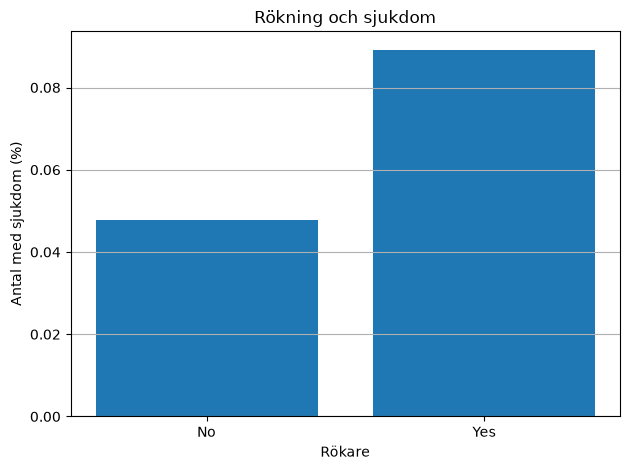

In [3]:
smoker_disease = df.groupby("smoker")["disease"].mean()

fig, bar = plt.subplots()

bar.bar(smoker_disease.index, smoker_disease.values)
bar.set_title("Rökning och sjukdom")
bar.set_xlabel("Rökare")
bar.set_ylabel("Antal med sjukdom (%)")
bar.grid(axis="y")
plt.tight_layout()

fig.savefig("../Figures/smoker_disease.png", dpi=150)


Andelen personer med sjukdom bland rökare och icke-rökare.

Cirka 8,9 % av rökarna har sjukdomen, jämfört med 4,8 % av icke-rökarna. Det innebär att sjukdomen är vanligare bland rökarna i denna data.

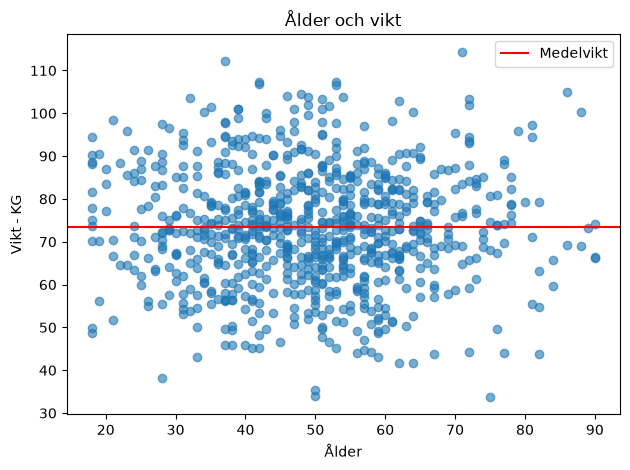

In [4]:
medelvikt = df["weight"].mean()

fig, scatter = plt.subplots()

scatter.scatter(df["age"], df["weight"], alpha=0.6)
scatter.set_title("Ålder och vikt")
scatter.set_xlabel("Ålder")
scatter.set_ylabel("Vikt - KG")
scatter.axhline(y=medelvikt, color="red", label="Medelvikt")
plt.tight_layout()
scatter.legend()

fig.savefig("../Figures/age_weight.png", dpi=150)


Varierar vikt beroende på ålder. Den röda linjen visar medelvikten, som är cirka 73,4 kg.

De flesta deltagarna väger mellan 50 och 90 kg, men det finns även några avvikande värden.

smoker
No     149.05
Yes    149.52
Name: systolic_bp, dtype: float64

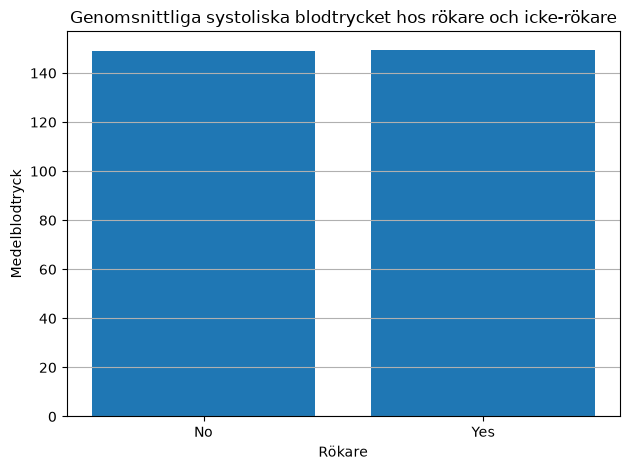

In [5]:
smoker_bp = df.groupby("smoker")["systolic_bp"].mean()
display(smoker_bp.round(2))

fig, bar = plt.subplots()

bar.bar(smoker_bp.index, smoker_bp.values)
bar.set_title("Genomsnittliga systoliska blodtrycket hos rökare och icke-rökare")
bar.set_xlabel("Rökare")
bar.set_ylabel("Medelblodtryck")
bar.grid(axis="y")
plt.tight_layout()

fig.savefig("../Figures/blodtryck hos rökare.png", dpi=150)


## Simulering kopplad till caset 

In [6]:
disease = df["disease"].to_numpy()

n = (len(disease))
andel = (disease == 1).sum() / n

print("Antal personer i data:", n)
print("Andel med sjukdom:", andel)

sim = df["disease"].sample(n=1000, replace=True, random_state=42)

print()
print("Verklig andel:", andel)
print("Simulerad andel:", sim.mean())

Antal personer i data: 800
Andel med sjukdom: 0.05875

Verklig andel: 0.05875
Simulerad andel: 0.063


I datasetet har 47 av 800 personer en sjukdom, vilket motsvarar 5,88 %.

Med hjälp av ett slumpmässigt stickprov med återläggning simulerades 1 000 observationer. Den simulerade andelen med sjukdom blev 6,30 %.

Resultatet ligger nära den ursprungliga andelen. Den mindre skillnaden kan förklaras av slumpmässig variation.

## Konfidensintervall

In [7]:
bp = df["systolic_bp"]

n = len(bp)
medelvärde = bp.mean()
std = bp.std()
se = std / np.sqrt(n)

print((medelvärde).round(2))

under = medelvärde - 1.96 * se
upper = medelvärde + 1.96 * se

print("95 % konfidensintervall:", (under).round(2), "-", (upper).round(2))



149.18
95 % konfidensintervall: 148.29 - 150.07


In [8]:
bp_boot = df["systolic_bp"].to_numpy()
rng = np.random.default_rng(42)

from Health_Analyzer import bootstrap_mean

R = 1000

means_n1000 = np.array([bootstrap_mean(bp_boot, rng) for _ in range(R)])

under_boot = np.percentile(means_n1000, 2.5) # lägsta 2,5 % av medelvärdena
upper_boot = np.percentile(means_n1000, 97.5) # 97,5 % av medelvärdena ligger

print("95 % konfidensintervall:", (under_boot).round(2), "-", (upper_boot).round(2))

95 % konfidensintervall: 148.32 - 150.03


# Metod - Konfidensintervall

Jag använde normalapproximation och bootstrap för att beräkna ett 95 % konfidensintervall för det genomsnittliga blodtrycket.

Normalapproximation passar eftersom vi har många observationer (800 st). Metoden fungerar bra med större stickprov, men kan vara mindre tillförlitlig om det finns många extrema värden.

Bootstrap använde jag för att jämföra med normalapproximationen och se om metoderna gav liknande resultat. Metoden bygger på slumpmässiga urval från den data vi redan har.

Båda metoderna gav nästan samma resultat, vilket tyder på att uppskattningen är ganska stabil.

Källa: Kursmaterial, vecka 6, övningsuppgift 2 och 4.

## Hypotesprövning

In [9]:
alpha = 0.05

smoker = df.loc[df["smoker"] == "Yes", "systolic_bp"]
non_smoker = df.loc[df["smoker"] == "No", "systolic_bp"]

n_smoke = len(smoker)
n_nonsmoke = len(non_smoker)


mean_smoker = smoker.mean()
mean_non_smoker = non_smoker.mean()
skillnad = mean_smoker - mean_non_smoker

t_stat, p_value = ttest_ind(
    smoker,
    non_smoker,
    equal_var=False,
    alternative="greater"
)

print("Rökare:", n_smoke, "Icke-rökare:", n_nonsmoke)
print("Medelvärde: blodtryck för rökare:", (mean_smoker).round(2))
print("Medelvärde: blodtryck för icke-rökare:", (mean_non_smoker).round(2))
print("Skillnad:", (skillnad).round(2))
print()
print("T-test:", (t_stat).round(3))
print("P-värde:", (p_value).round(2))

Rökare: 213 Icke-rökare: 587
Medelvärde: blodtryck för rökare: 149.52
Medelvärde: blodtryck för icke-rökare: 149.05
Skillnad: 0.47

T-test: 0.45
P-värde: 0.33


# Hypotesprövning – Rökare och blodtryck

H0 (nollhypotes): Rökare har inte högre genomsnittligt blodtryck än icke-rökare.

H1 (mothypotes): Rökare har högre genomsnittligt blodtryck än icke-rökare.

Jag använde t-test för att jämföra medelblodtrycket mellan grupperna. Metoden passar eftersom vi jämför två oberoende grupper och inte behöver anta att de har samma varians.

Rökarna hade ett något högre medelblodtryck, men skillnaden var bara 0,47. P-värdet var ungefär 0,33, vilket är högre än signifikansnivån 0,05.

Vi kan därför inte förkasta nollhypotesen. Det finns inte tillräckligt med statistiskt stöd för att säga att rökare har högre genomsnittligt blodtryck i den population vi undersöker.

Källa: Kursmaterial, vecka 6, övningsuppgift 7.

## Power

In [30]:
antal_skillnad = 0
R = 1000

for i in range(R):
    sim_smoker = smoker.sample(n=len(smoker), replace=True)
    sim_non_smoker = non_smoker.sample(n=len(non_smoker), replace=True)

    sim_smoker = sim_smoker - smoker.mean() + non_smoker.mean() + 2

    t_stat, p_value = ttest_ind(
        sim_smoker,
        sim_non_smoker,
        equal_var=False,
        alternative="greater"
    )

    if p_value < 0.05:
        antal_skillnad += 1

power = antal_skillnad / R

print("Antal signifikanta tester:", antal_skillnad)
print("Power:", power * 100, "%")

Antal signifikanta tester: 625
Power: 62.5 %
